## Part B — Dataset Understanding and Preparation

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# The Excel file is kept in the same folder as this notebook.
DATA_FILE = "RealEstate_HousePrice_Dataset.xlsx"
df = pd.read_excel(DATA_FILE)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 4200 rows × 12 columns


,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.60,23,11.90,5220,1,0,0,40275084
1,100002,1560,3,3,6.30,13,15.80,3882,1,0,13,26812029
2,100003,2071,4,3,5.80,9,21.10,4488,0,0,9,29315677
3,100004,2640,5,3,7.70,12,7.90,3614,1,1,4,47712959
4,100005,1498,3,3,3.80,15,24.00,2663,0,0,15,17724566


In [2]:
print("Column data types:")
display(df.dtypes.rename("data_type").to_frame())

print("Missing values by column:")
display(df.isna().sum().rename("missing_values").to_frame())

print("Numerical summary:")
display(df.describe().T)

Column data types:


,data_type
house_id,int64
area_sqft,int64
bedrooms,int64
bathrooms,int64
location_score,float64
age_years,int64
distance_city_km,float64
lot_size_sqft,int64
has_garage,int64
has_pool,int64


Missing values by column:


,missing_values
house_id,0
area_sqft,0
bedrooms,0
bathrooms,0
location_score,0
age_years,0
distance_city_km,0
lot_size_sqft,0
has_garage,0
has_pool,0


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
house_id,"4,200.00","102,100.50","1,212.58","100,001.00","101,050.75","102,100.50","103,150.25","104,200.00"
area_sqft,"4,200.00","1,667.36",630.34,450.00,"1,226.75","1,660.00","2,084.25","4,202.00"
bedrooms,"4,200.00",3.70,1.57,1.00,3.00,4.00,5.00,7.00
bathrooms,"4,200.00",2.83,1.15,1.00,2.00,3.00,4.00,6.00
location_score,"4,200.00",5.61,2.14,1.00,4.00,5.70,7.30,10.00
age_years,"4,200.00",23.83,13.95,1.00,13.00,21.00,32.00,80.00
distance_city_km,"4,200.00",18.19,8.67,1.00,11.80,17.80,24.20,47.60
lot_size_sqft,"4,200.00","3,366.33","1,658.23",800.00,"2,122.50","3,188.00","4,364.25","12,938.00"
has_garage,"4,200.00",0.64,0.48,0.00,0.00,1.00,1.00,1.00
has_pool,"4,200.00",0.10,0.29,0.00,0.00,0.00,0.00,1.00


### Identify independent and dependent variables

In [3]:
target = "house_price_inr"
id_column = "house_id"
feature_columns = [column for column in df.columns if column not in [target, id_column]]

X = df[feature_columns].copy()
y = df[target].copy()

print("Independent variables:")
print(feature_columns)
print(f"Dependent variable: {target}")
print(f"Missing values in selected data: {int(X.isna().sum().sum() + y.isna().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")

Independent variables:
['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']
Dependent variable: house_price_inr
Missing values in selected data: 0
Duplicate rows: 0


### Visualize feature relationships

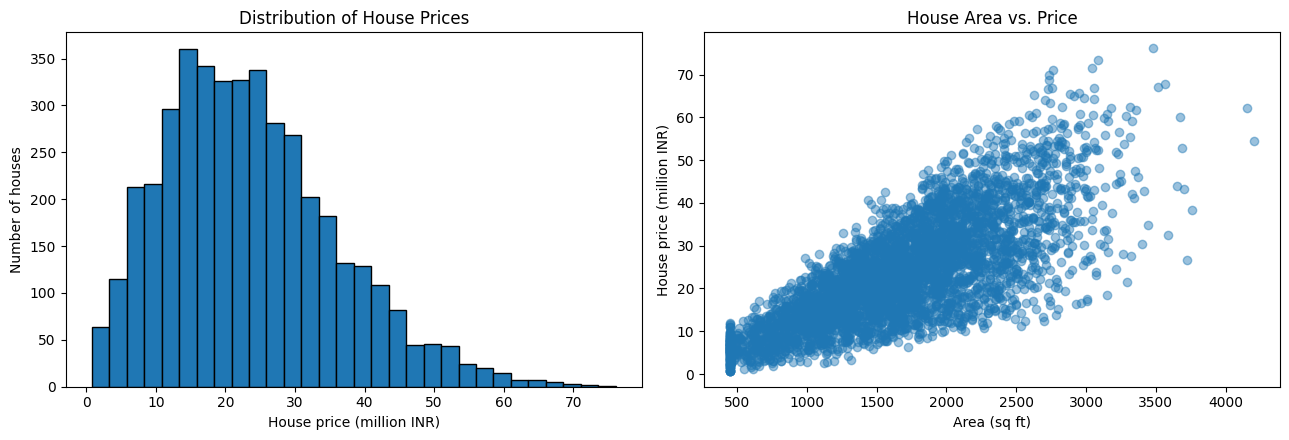

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df[target] / 1_000_000, bins=30, edgecolor="black")
axes[0].set_title("Distribution of House Prices")
axes[0].set_xlabel("House price (million INR)")
axes[0].set_ylabel("Number of houses")

axes[1].scatter(df["area_sqft"], df[target] / 1_000_000, alpha=0.45)
axes[1].set_title("House Area vs. Price")
axes[1].set_xlabel("Area (sq ft)")
axes[1].set_ylabel("House price (million INR)")
plt.tight_layout()
plt.show()

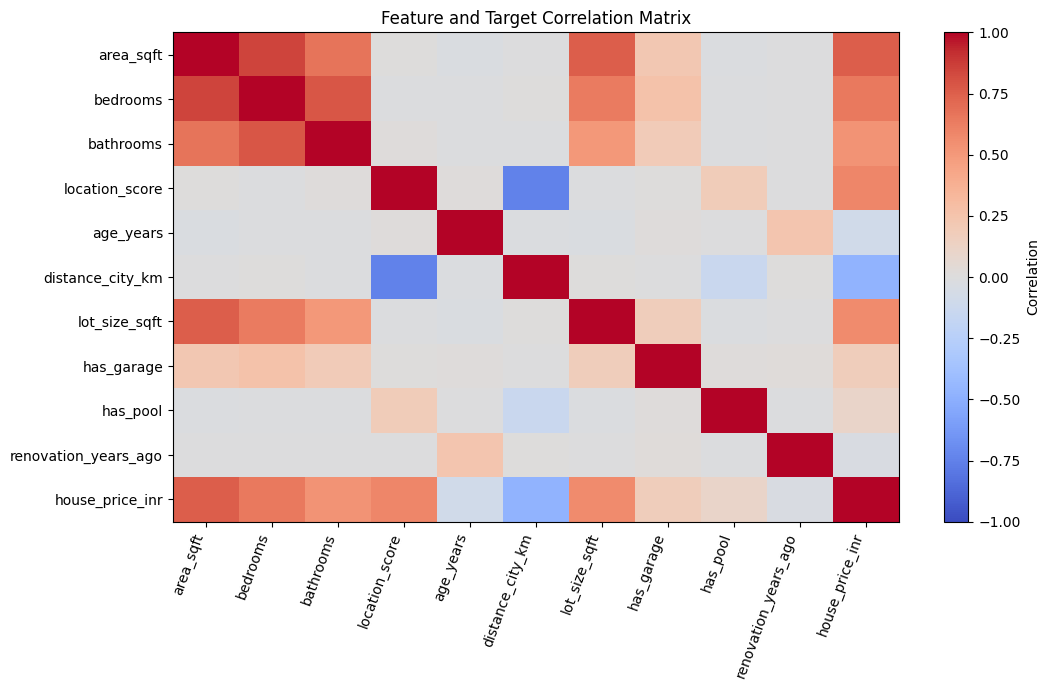

,correlation_with_price
house_price_inr,1.00
area_sqft,0.76
bedrooms,0.64
location_score,0.59
lot_size_sqft,0.57
bathrooms,0.53
has_garage,0.18
has_pool,0.10
renovation_years_ago,-0.04
age_years,-0.09


In [5]:
corr = df[feature_columns + [target]].corr(numeric_only=True)
plt.figure(figsize=(11, 7))
plt.imshow(corr, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=70, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Feature and Target Correlation Matrix")
plt.tight_layout()
plt.show()

display(corr[[target]].sort_values(target, ascending=False).rename(columns={target: "correlation_with_price"}))

### Training and testing split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training rows: {len(X_train)}")
print(f"Testing rows:  {len(X_test)}")
print(f"Training share: {len(X_train) / len(df):.0%}")
print(f"Testing share:  {len(X_test) / len(df):.0%}")

Training rows: 3360
Testing rows:  840
Training share: 80%
Testing share:  20%


## Part C — Simple Linear Regression

In [7]:
simple_model = LinearRegression()
simple_model.fit(X_train[["area_sqft"]], y_train)
simple_pred = simple_model.predict(X_test[["area_sqft"]])

slope = simple_model.coef_[0]
intercept = simple_model.intercept_
print(f"Intercept: ₹{intercept:,.2f}")
print(f"Slope: ₹{slope:,.2f} per additional square foot")
print("Interpretation: the slope is the model's estimated average price change for one additional square foot.")

Intercept: ₹-1,163,519.18
Slope: ₹14,788.31 per additional square foot
Interpretation: the slope is the model's estimated average price change for one additional square foot.


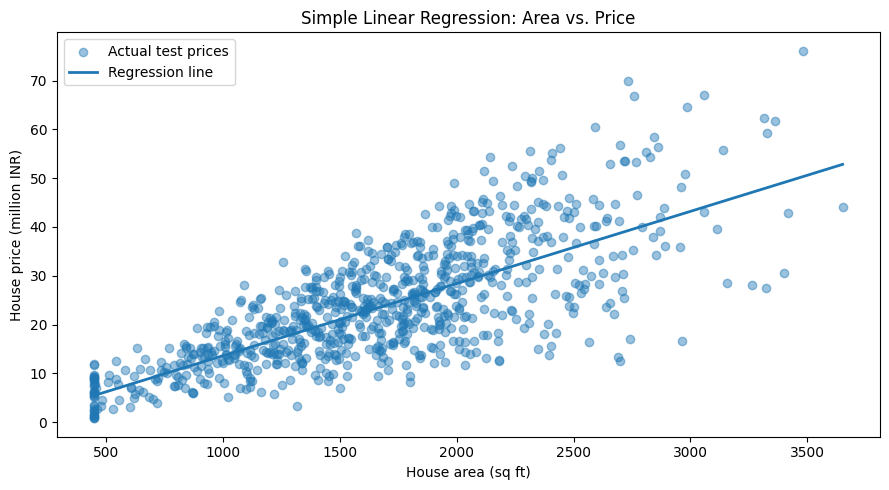

In [8]:
plot_data = pd.DataFrame({"area_sqft": X_test["area_sqft"], "actual_price": y_test, "predicted_price": simple_pred})
plot_data = plot_data.sort_values("area_sqft")

plt.figure(figsize=(9, 5))
plt.scatter(plot_data["area_sqft"], plot_data["actual_price"] / 1_000_000, alpha=0.45, label="Actual test prices")
plt.plot(plot_data["area_sqft"], plot_data["predicted_price"] / 1_000_000, linewidth=2, label="Regression line")
plt.xlabel("House area (sq ft)")
plt.ylabel("House price (million INR)")
plt.title("Simple Linear Regression: Area vs. Price")
plt.legend()
plt.tight_layout()
plt.show()

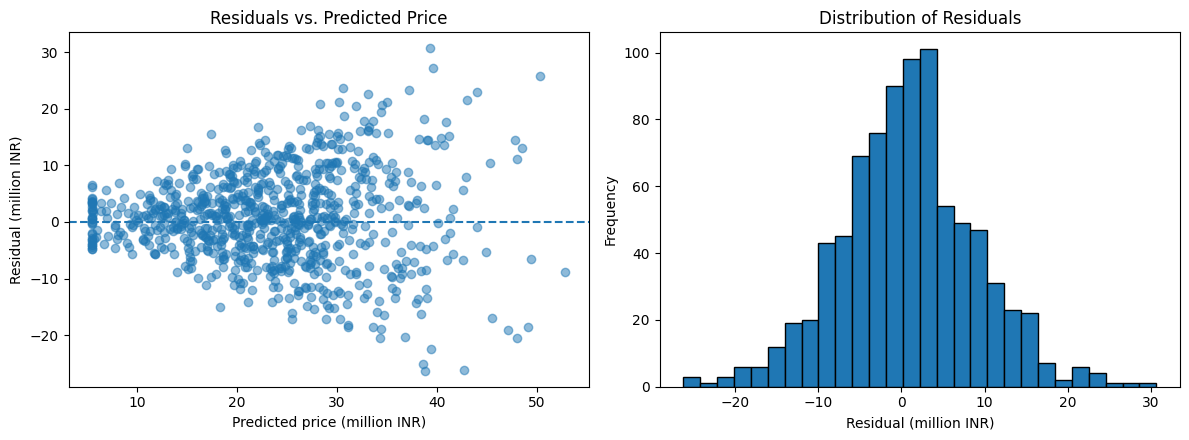

Assumption check: look for a roughly pattern-free residual cloud with similar vertical spread.
A strong curve may indicate non-linearity; a funnel shape may indicate non-constant error variance.
A histogram alone cannot prove that residuals are normally distributed.


In [9]:
simple_residuals = y_test - simple_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(simple_pred / 1_000_000, simple_residuals / 1_000_000, alpha=0.5)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs. Predicted Price")
axes[0].set_xlabel("Predicted price (million INR)")
axes[0].set_ylabel("Residual (million INR)")

axes[1].hist(simple_residuals / 1_000_000, bins=28, edgecolor="black")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (million INR)")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Assumption check: look for a roughly pattern-free residual cloud with similar vertical spread.")
print("A strong curve may indicate non-linearity; a funnel shape may indicate non-constant error variance.")
print("A histogram alone cannot prove that residuals are normally distributed.")

## Part D — Model Evaluation Metrics

In [10]:
def regression_metrics(y_true, y_pred, number_of_features):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    p = number_of_features
    adjusted_r2 = np.nan if n <= p + 1 else 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {"MSE": mse, "MAE": mae, "RMSE": rmse, "R2": r2, "Adjusted_R2": adjusted_r2}

simple_metrics = regression_metrics(y_test, simple_pred, 1)
simple_metrics_df = pd.DataFrame([simple_metrics], index=["Simple Linear Regression"])
display(simple_metrics_df.style.format({
    "MSE": "₹{:,.0f}²", "MAE": "₹{:,.0f}", "RMSE": "₹{:,.0f}",
    "R2": "{:.4f}", "Adjusted_R2": "{:.4f}"
}))
print(f"On average, absolute test error is about ₹{simple_metrics['MAE']:,.0f} (MAE).")
print(f"The model explains about {simple_metrics['R2']:.1%} of test-set price variation according to R².")

,MSE,MAE,RMSE,R2,Adjusted_R2
Simple Linear Regression,"₹66,989,260,021,849²","₹6,294,594","₹8,184,697",0.5625,0.5620


On average, absolute test error is about ₹6,294,594 (MAE).
The model explains about 56.3% of test-set price variation according to R².


## Part E — Multiple Linear Regression

In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_pred = multiple_model.predict(X_test)
multiple_metrics = regression_metrics(y_test, multiple_pred, X_train.shape[1])

comparison = pd.DataFrame(
    [simple_metrics, multiple_metrics],
    index=["Simple Linear Regression", "Multiple Linear Regression"]
)
display(comparison.style.format({
    "MSE": "₹{:,.0f}²", "MAE": "₹{:,.0f}", "RMSE": "₹{:,.0f}",
    "R2": "{:.4f}", "Adjusted_R2": "{:.4f}"
}))

coef_table = pd.DataFrame({"feature": feature_columns, "coefficient": multiple_model.coef_})
display(coef_table.sort_values("coefficient", key=lambda column: column.abs(), ascending=False))
print("Coefficients describe the model's change in predicted price for a one-unit feature change, holding other inputs fixed.")
print("Their size depends on each feature's units; coefficient magnitude alone is not a reliable importance ranking.")

,MSE,MAE,RMSE,R2,Adjusted_R2
Simple Linear Regression,"₹66,989,260,021,849²","₹6,294,594","₹8,184,697",0.5625,0.5620
Multiple Linear Regression,"₹12,592,918,884,128²","₹2,604,991","₹3,548,650",0.9178,0.9168


,feature,coefficient
3,location_score,"3,073,173.50"
8,has_pool,"455,290.23"
1,bedrooms,"197,643.11"
2,bathrooms,"185,944.54"
5,distance_city_km,"-98,965.16"
7,has_garage,"93,924.36"
4,age_years,"-65,609.24"
9,renovation_years_ago,"-21,435.91"
0,area_sqft,"13,795.94"
6,lot_size_sqft,103.51


Coefficients describe the model's change in predicted price for a one-unit feature change, holding other inputs fixed.
Their size depends on each feature's units; coefficient magnitude alone is not a reliable importance ranking.


## Part F — Polynomial Regression

,MSE,MAE,RMSE,R2,Adjusted_R2
Simple Linear Regression,"₹66,989,260,021,849²","₹6,294,594","₹8,184,697",0.5625,0.5620
Polynomial Regression (degree 2),"₹66,962,947,122,198²","₹6,292,395","₹8,183,089",0.5627,0.5616
Polynomial Regression (degree 3),"₹66,935,016,197,794²","₹6,289,615","₹8,181,382",0.5629,0.5613


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


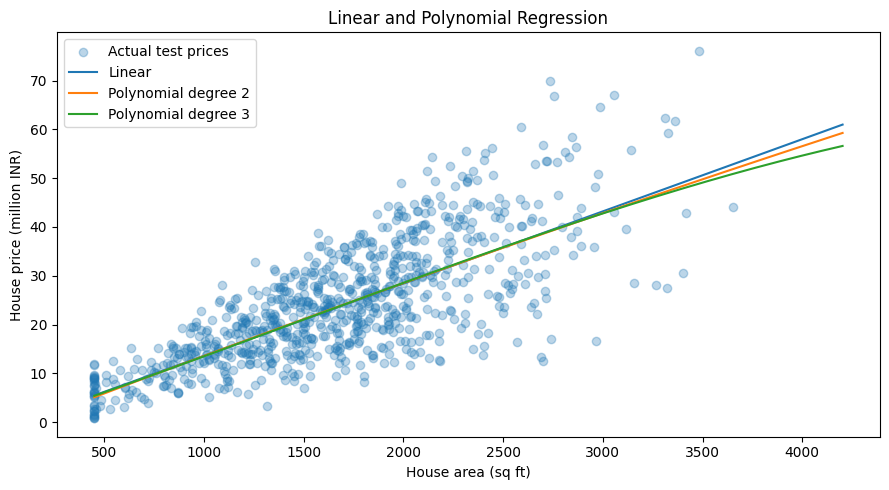

In [ ]:
poly_results = {"Simple Linear Regression": (simple_metrics, simple_pred)}
poly_models = {}

for degree in [2, 3]:
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    model.fit(X_train[["area_sqft"]], y_train)
    pred = model.predict(X_test[["area_sqft"]])
    metrics = regression_metrics(y_test, pred, degree)
    poly_results[f"Polynomial Regression (degree {degree})"] = (metrics, pred)
    poly_models[degree] = model

poly_comparison = pd.DataFrame({name: values[0] for name, values in poly_results.items()}).T
display(poly_comparison.style.format({
    "MSE": "₹{:,.0f}²", "MAE": "₹{:,.0f}", "RMSE": "₹{:,.0f}",
    "R2": "{:.4f}", "Adjusted_R2": "{:.4f}"
}))

area_grid = np.linspace(df["area_sqft"].min(), df["area_sqft"].max(), 250).reshape(-1, 1)
plt.figure(figsize=(9, 5))
plt.scatter(X_test["area_sqft"], y_test / 1_000_000, alpha=0.3, label="Actual test prices")
plt.plot(area_grid.ravel(), simple_model.predict(area_grid) / 1_000_000, label="Linear")
for degree, model in poly_models.items():
    plt.plot(area_grid.ravel(), model.predict(area_grid) / 1_000_000, label=f"Polynomial degree {degree}")
plt.xlabel("House area (sq ft)")
plt.ylabel("House price (million INR)")
plt.title("Linear and Polynomial Regression")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
train_poly_rows = []
for degree in [1, 2, 3]:
    if degree == 1:
        model = LinearRegression()
        model.fit(X_train[["area_sqft"]], y_train)
        train_prediction = model.predict(X_train[["area_sqft"]])
        test_prediction = model.predict(X_test[["area_sqft"]])
    else:
        model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
        model.fit(X_train[["area_sqft"]], y_train)
        train_prediction = model.predict(X_train[["area_sqft"]])
        test_prediction = model.predict(X_test[["area_sqft"]])
    train_poly_rows.append({
        "Model": f"Degree {degree}",
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_prediction))
    })

display(pd.DataFrame(train_poly_rows).set_index("Model").style.format("₹{:,.0f}"))
print("A large train/test error gap can be a warning sign of overfitting.")
print("If both errors remain high, the model may be underfitting or a single feature may not contain enough information.")

,Train RMSE,Test RMSE
Model,,
Degree 1,"₹8,104,428","₹8,184,697"
Degree 2,"₹8,102,913","₹8,183,089"
Degree 3,"₹8,101,891","₹8,181,382"


A large train/test error gap can be a warning sign of overfitting.
If both errors remain high, the model may be underfitting or a single feature may not contain enough information.


## Part G — Gradient Descent Optimization

In [14]:
# Standardize the single feature and target for a stable from-scratch comparison.
x_raw = X_train["area_sqft"].to_numpy(dtype=float)
x_mean, x_std = x_raw.mean(), x_raw.std()
x_scaled = (x_raw - x_mean) / x_std

y_raw = y_train.to_numpy(dtype=float)
y_mean, y_std = y_raw.mean(), y_raw.std()
y_scaled = (y_raw - y_mean) / y_std

x_test_scaled = (X_test["area_sqft"].to_numpy(dtype=float) - x_mean) / x_std
y_test_array = y_test.to_numpy(dtype=float)

def mse_loss(X_values, y_values, weights):
    errors = X_values @ weights - y_values
    return np.mean(errors ** 2)

def run_gradient_descent(method, learning_rate=0.03, epochs=120, batch_size=32, seed=42):
    rng = np.random.default_rng(seed)
    X_design = np.column_stack([np.ones(len(x_scaled)), x_scaled])
    weights = np.zeros(2)
    history = []
    start = time.perf_counter()

    for epoch in range(epochs):
        if method == "batch":
            batches = [np.arange(len(X_design))]
        elif method == "stochastic":
            order = rng.permutation(len(X_design))
            batches = [order[i:i+1] for i in range(len(order))]
        else:
            order = rng.permutation(len(X_design))
            batches = [order[i:i+batch_size] for i in range(0, len(order), batch_size)]

        for indices in batches:
            xb, yb = X_design[indices], y_scaled[indices]
            error = xb @ weights - yb
            gradient = (2 / len(indices)) * (xb.T @ error)
            weights -= learning_rate * gradient

        history.append(mse_loss(X_design, y_scaled, weights))

    elapsed = time.perf_counter() - start
    test_design = np.column_stack([np.ones(len(x_test_scaled)), x_test_scaled])
    test_scaled_prediction = test_design @ weights
    test_prediction = test_scaled_prediction * y_std + y_mean
    metrics = regression_metrics(y_test_array, test_prediction, 1)
    return {"weights": weights, "history": history, "seconds": elapsed, "metrics": metrics}

gd_results = {
    "Batch GD": run_gradient_descent("batch", learning_rate=0.03, epochs=120),
    "Stochastic GD": run_gradient_descent("stochastic", learning_rate=0.01, epochs=30),
    "Mini-Batch GD": run_gradient_descent("mini", learning_rate=0.03, epochs=120, batch_size=32)
}

gd_summary = []
for name, result in gd_results.items():
    gd_summary.append({
        "Method": name,
        "Final standardized training MSE": result["history"][-1],
        "Test MAE (INR)": result["metrics"]["MAE"],
        "Test RMSE (INR)": result["metrics"]["RMSE"],
        "Test R2": result["metrics"]["R2"],
        "Training time (seconds)": result["seconds"]
    })

display(pd.DataFrame(gd_summary).set_index("Method").style.format({
    "Final standardized training MSE": "{:.6f}",
    "Test MAE (INR)": "₹{:,.0f}",
    "Test RMSE (INR)": "₹{:,.0f}",
    "Test R2": "{:.4f}",
    "Training time (seconds)": "{:.4f}"
}))

,Final standardized training MSE,Test MAE (INR),Test RMSE (INR),Test R2,Training time (seconds)
Method,,,,,
Batch GD,0.427693,"₹6,294,539","₹8,184,834",0.5625,0.0081
Stochastic GD,0.428452,"₹6,322,628","₹8,202,150",0.5607,0.5350
Mini-Batch GD,0.428133,"₹6,311,619","₹8,209,918",0.5598,0.0812


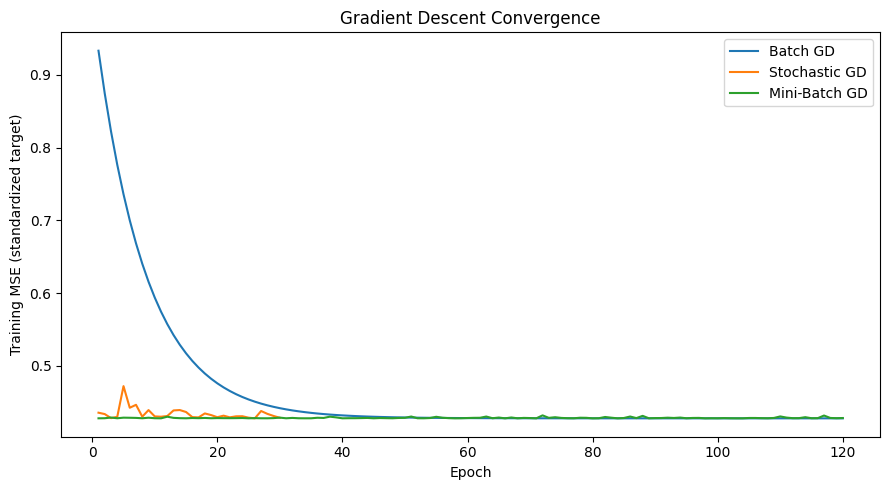

Batch GD updates once per epoch using all training rows.
Stochastic GD updates after each individual row, so its path is noisier.
Mini-Batch GD updates using small groups, balancing update frequency and stability.
Measured time depends on hardware and implementation; compare it on the same computer.


In [15]:
plt.figure(figsize=(9, 5))
for name, result in gd_results.items():
    plt.plot(range(1, len(result["history"]) + 1), result["history"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Training MSE (standardized target)")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.tight_layout()
plt.show()

print("Batch GD updates once per epoch using all training rows.")
print("Stochastic GD updates after each individual row, so its path is noisier.")
print("Mini-Batch GD updates using small groups, balancing update frequency and stability.")
print("Measured time depends on hardware and implementation; compare it on the same computer.")

## Part H — Bias–Variance and Model Diagnostics

In [16]:
diagnostic_models = {
    "Simple Linear": (simple_model, X_train[["area_sqft"]], X_test[["area_sqft"]]),
    "Multiple Linear": (multiple_model, X_train, X_test),
    "Polynomial degree 2": (poly_models[2], X_train[["area_sqft"]], X_test[["area_sqft"]]),
    "Polynomial degree 3": (poly_models[3], X_train[["area_sqft"]], X_test[["area_sqft"]])
}

diagnostics = []
for name, (model, xtr, xte) in diagnostic_models.items():
    train_pred = model.predict(xtr)
    test_pred = model.predict(xte)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    diagnostics.append({
        "Model": name,
        "Train RMSE (INR)": train_rmse,
        "Test RMSE (INR)": test_rmse,
        "Train-Test Gap (INR)": test_rmse - train_rmse,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

diagnostic_df = pd.DataFrame(diagnostics).set_index("Model")
display(diagnostic_df.style.format({
    "Train RMSE (INR)": "₹{:,.0f}",
    "Test RMSE (INR)": "₹{:,.0f}",
    "Train-Test Gap (INR)": "₹{:,.0f}",
    "Train R2": "{:.4f}",
    "Test R2": "{:.4f}"
}))

best_model_name = diagnostic_df["Test RMSE (INR)"].idxmin()
print(f"Lowest test RMSE among these models: {best_model_name}")
print("A smaller test error is preferable here, but the final choice should also consider simplicity and reliability.")
print("This train/test comparison is a practical diagnostic, not a formal measurement of pure bias and variance.")

,Train RMSE (INR),Test RMSE (INR),Train-Test Gap (INR),Train R2,Test R2
Model,,,,,
Simple Linear,"₹8,104,428","₹8,184,697","₹80,269",0.5723,0.5625
Multiple Linear,"₹3,400,099","₹3,548,650","₹148,551",0.9247,0.9178
Polynomial degree 2,"₹8,102,913","₹8,183,089","₹80,177",0.5725,0.5627
Polynomial degree 3,"₹8,101,891","₹8,181,382","₹79,492",0.5726,0.5629


Lowest test RMSE among these models: Multiple Linear
A smaller test error is preferable here, but the final choice should also consider simplicity and reliability.
This train/test comparison is a practical diagnostic, not a formal measurement of pure bias and variance.


## Part I — Final Analysis and Reporting

In [17]:
all_model_metrics = {
    "Simple Linear Regression": simple_metrics,
    "Multiple Linear Regression": multiple_metrics,
    "Polynomial Regression (degree 2)": poly_results["Polynomial Regression (degree 2)"][0],
    "Polynomial Regression (degree 3)": poly_results["Polynomial Regression (degree 3)"][0]
}
final_table = pd.DataFrame(all_model_metrics).T.sort_values("RMSE")
display(final_table.style.format({
    "MSE": "₹{:,.0f}²", "MAE": "₹{:,.0f}", "RMSE": "₹{:,.0f}",
    "R2": "{:.4f}", "Adjusted_R2": "{:.4f}"
}))

best_name = final_table.index[0]
best_row = final_table.iloc[0]
print("FINAL REPORT")
print("-" * 60)
print(f"Best model by test RMSE: {best_name}")
print(f"Test RMSE: ₹{best_row['RMSE']:,.0f}")
print(f"Test MAE:  ₹{best_row['MAE']:,.0f}")
print(f"Test R²:   {best_row['R2']:.4f}")
print()
print("Business interpretation:")
print("The model can support an initial price estimate from recorded property features.")
print("Predictions should be treated as estimates, not guaranteed selling prices.")
print("Before business deployment, validate on newer properties, inspect unusual errors, and monitor performance over time.")
print()
gd_best = min(gd_results, key=lambda name: gd_results[name]["metrics"]["RMSE"])
print(f"Gradient descent method with lowest test RMSE in this run: {gd_best}")
print("Optimization time and convergence depend on learning rate, number of epochs, batch size, and hardware.")

,MSE,MAE,RMSE,R2,Adjusted_R2
Multiple Linear Regression,"₹12,592,918,884,128²","₹2,604,991","₹3,548,650",0.9178,0.9168
Polynomial Regression (degree 3),"₹66,935,016,197,794²","₹6,289,615","₹8,181,382",0.5629,0.5613
Polynomial Regression (degree 2),"₹66,962,947,122,198²","₹6,292,395","₹8,183,089",0.5627,0.5616
Simple Linear Regression,"₹66,989,260,021,849²","₹6,294,594","₹8,184,697",0.5625,0.5620


FINAL REPORT
------------------------------------------------------------
Best model by test RMSE: Multiple Linear Regression
Test RMSE: ₹3,548,650
Test MAE:  ₹2,604,991
Test R²:   0.9178

Business interpretation:
The model can support an initial price estimate from recorded property features.
Predictions should be treated as estimates, not guaranteed selling prices.
Before business deployment, validate on newer properties, inspect unusual errors, and monitor performance over time.

Gradient descent method with lowest test RMSE in this run: Batch GD
Optimization time and convergence depend on learning rate, number of epochs, batch size, and hardware.
